# JobShield
## 05 — Final Model Evaluation

### Objectives
1. Compare Logistic Regression and DNN performance.
2. Examine precision-recall trade-offs.
3. Select a DNN classification threshold using validation data.
4. Evaluate the selected model on untouched test data.
5. Generate final confusion matrices and results tables.
6. Save the chosen threshold for the application.

### Evaluation Policy
The threshold is selected using validation data only.

The final test dataset is used to estimate generalisation
performance, not to make further modelling decisions.

In [1]:
import json
import sys
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def find_project_root():
    current = Path.cwd()

    for folder in [current] + list(current.parents):
        model_file = folder / "models" / "jobshield_dnn.keras"

        if model_file.is_file():
            return folder

    raise FileNotFoundError(
        "Cannot find the trained JobShield DNN."
    )


PROJECT_ROOT = find_project_root()

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import prepare_features

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

preprocessor = joblib.load(
    MODEL_DIR / "preprocessor.joblib"
)

baseline = joblib.load(
    MODEL_DIR / "logistic_baseline.joblib"
)

dnn = tf.keras.models.load_model(
    MODEL_DIR / "jobshield_dnn.keras",
    compile=False
)

X_val = sparse.load_npz(
    DATA_DIR / "validation_features.npz"
)

val_df = pd.read_csv(
    DATA_DIR / "validation.csv",
    keep_default_na=False
)

y_val = val_df["fraudulent"].astype(int).to_numpy()

assert X_val.shape[0] == len(y_val)

print("Models loaded successfully.")
print("Validation observations:", len(y_val))
print("Feature count:", X_val.shape[1])

c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Divyabhanu Rana\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.3

Models loaded successfully.
Validation observations: 2640
Feature count: 3868


In [2]:
def evaluate_predictions(y_true, scores, threshold=0.5):

    predictions = (scores >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "Average Precision": average_precision_score(
            y_true, scores
        )
    }


baseline_scores = baseline.predict_proba(X_val)[:, 1]

dnn_scores = dnn.predict(
    X_val.toarray().astype(np.float32),
    batch_size=256,
    verbose=0
).ravel()

assert len(baseline_scores) == len(y_val)
assert len(dnn_scores) == len(y_val)

baseline_metrics = evaluate_predictions(
    y_val, baseline_scores
)

dnn_metrics = evaluate_predictions(
    y_val, dnn_scores
)

comparison = pd.DataFrame(
    [baseline_metrics, dnn_metrics],
    index=["Logistic Regression", "DNN"]
)

print("VALIDATION MODEL COMPARISON")
display(comparison.round(4))

VALIDATION MODEL COMPARISON


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Logistic Regression,0.9720,0.6421,0.9531,0.7673,0.9938,0.9097
DNN,0.9769,0.6914,0.9453,0.7987,0.9968,0.9537


## 1. Threshold Selection

The default classification threshold is 0.50.

A lower threshold may detect more fraudulent advertisements,
but it can also flag more legitimate advertisements incorrectly.

For this experiment, we will seek a validation recall
of at least 95%, while selecting the candidate threshold
with the highest F1-score.

If no candidate satisfies the recall requirement,
we will select the highest-F1 candidate and document this.

The threshold is selected without examining test outcomes.

Selected threshold: 0.485
Recall requirement met: True

Selected validation performance:


,Value
Threshold,0.485000
Precision,0.694915
Recall,0.960938
F1,0.806557


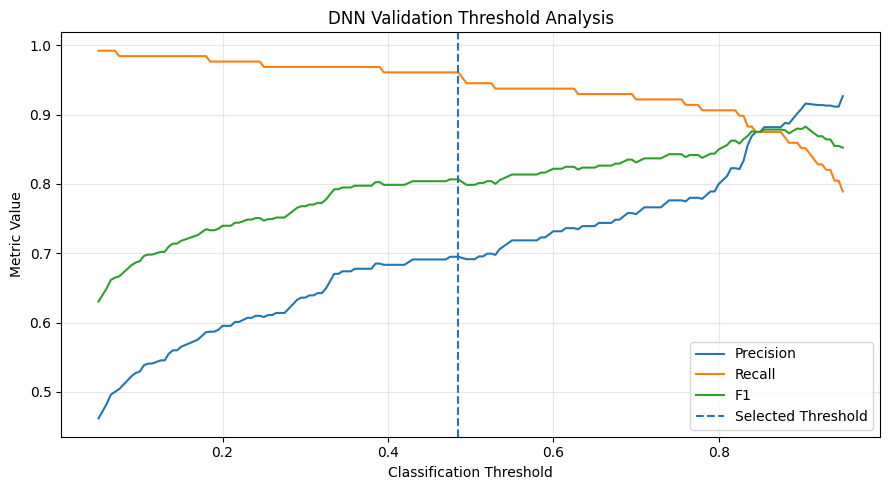

In [3]:
thresholds = np.linspace(0.05, 0.95, 181)

records = []

for threshold in thresholds:

    predictions = (dnn_scores >= threshold).astype(int)

    records.append({
        "Threshold": float(threshold),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(records)

MIN_RECALL = 0.95

eligible = threshold_results[
    threshold_results["Recall"] >= MIN_RECALL
]

recall_requirement_met = not eligible.empty

if recall_requirement_met:
    candidates = eligible
else:
    candidates = threshold_results

best_row = candidates.sort_values(
    by=["F1", "Precision", "Threshold"],
    ascending=[False, False, False]
).iloc[0]

selected_threshold = float(best_row["Threshold"])

print("Selected threshold:", round(selected_threshold, 3))
print("Recall requirement met:", recall_requirement_met)

print("\nSelected validation performance:")
display(best_row.to_frame(name="Value"))

threshold_results.to_csv(
    REPORT_DIR / "threshold_analysis.csv",
    index=False
)

plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        threshold_results["Threshold"],
        threshold_results[metric],
        label=metric
    )

plt.axvline(
    selected_threshold,
    linestyle="--",
    label="Selected Threshold"
)

plt.title("DNN Validation Threshold Analysis")
plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "threshold_analysis.png",
    dpi=200
)

plt.show()

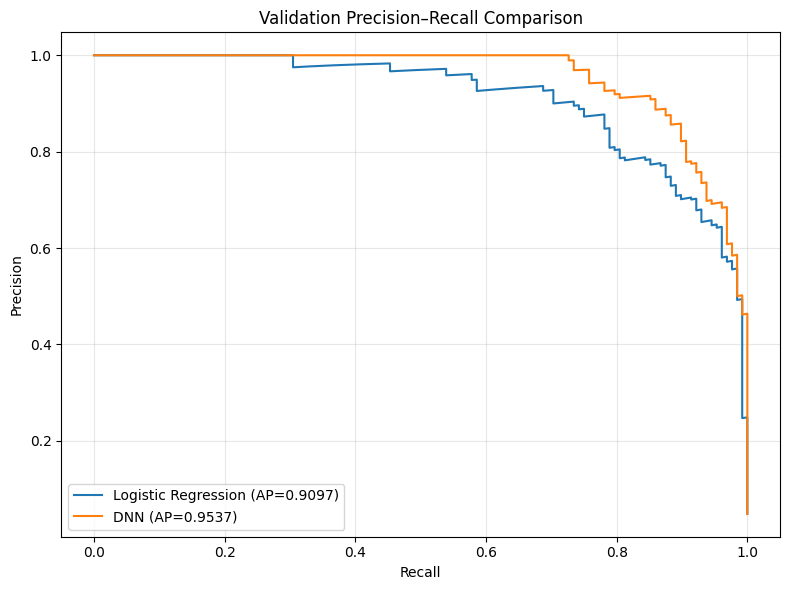

In [4]:
base_precision, base_recall, _ = precision_recall_curve(
    y_val,
    baseline_scores
)

dnn_precision, dnn_recall, _ = precision_recall_curve(
    y_val,
    dnn_scores
)

plt.figure(figsize=(8, 6))

plt.plot(
    base_recall,
    base_precision,
    label=(
        "Logistic Regression "
        f"(AP={average_precision_score(y_val, baseline_scores):.4f})"
    )
)

plt.plot(
    dnn_recall,
    dnn_precision,
    label=(
        "DNN "
        f"(AP={average_precision_score(y_val, dnn_scores):.4f})"
    )
)

plt.title("Validation Precision–Recall Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "precision_recall_comparison.png",
    dpi=200
)

plt.show()

In [5]:
threshold_config = {
    "model": "jobshield_dnn.keras",
    "decision_threshold": selected_threshold,
    "selection_dataset": "validation",
    "minimum_requested_recall": MIN_RECALL,
    "recall_requirement_met": bool(recall_requirement_met),
    "validation_recall": float(best_row["Recall"]),
    "validation_f1": float(best_row["F1"]),
    "score_calibrated": False
}

threshold_path = MODEL_DIR / "decision_threshold.json"

with open(threshold_path, "w", encoding="utf-8") as file:
    json.dump(
        threshold_config,
        file,
        indent=4
    )

print("Threshold configuration saved.")
print(json.dumps(threshold_config, indent=4))

Threshold configuration saved.
{
    "model": "jobshield_dnn.keras",
    "decision_threshold": 0.48499999999999993,
    "selection_dataset": "validation",
    "minimum_requested_recall": 0.95,
    "recall_requirement_met": true,
    "validation_recall": 0.9609375,
    "validation_f1": 0.8065573770491803,
    "score_calibrated": false
}


## 2. Final Test Evaluation

The test dataset was held out during model development.

We will now evaluate:

1. Logistic Regression at threshold 0.50.
2. DNN at threshold 0.50.
3. DNN at the validation-selected threshold.

The selected DNN remains our primary model.

No model parameters or classification thresholds will
be changed based on test-set outcomes.

In [6]:
test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    keep_default_na=False
)

X_test_raw = prepare_features(test_df)

y_test = test_df["fraudulent"].astype(int).to_numpy()

# Reuse the training-fitted feature transformer
X_test = preprocessor.transform(X_test_raw)

X_test = sparse.csr_matrix(
    X_test,
    dtype=np.float32
)

assert X_test.shape[0] == len(y_test)
assert X_test.shape[1] == X_val.shape[1]

# Generate predictions
baseline_test_scores = baseline.predict_proba(
    X_test
)[:, 1]

dnn_test_scores = dnn.predict(
    X_test.toarray(),
    batch_size=256,
    verbose=0
).ravel()

test_results = pd.DataFrame({
    "Logistic Regression (0.50)": evaluate_predictions(
        y_test, baseline_test_scores, 0.50
    ),
    "DNN (0.50)": evaluate_predictions(
        y_test, dnn_test_scores, 0.50
    ),
    "DNN (Selected Threshold)": evaluate_predictions(
        y_test, dnn_test_scores, selected_threshold
    )
}).T

print("FINAL TEST RESULTS")
display(test_results.round(4))

test_results.to_csv(
    REPORT_DIR / "final_test_results.csv"
)

print("\nFinal test results saved successfully.")

FINAL TEST RESULTS


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Logistic Regression (0.50),0.9750,0.6761,0.9297,0.7829,0.9932,0.9181
DNN (0.50),0.9792,0.7386,0.8828,0.8043,0.9925,0.9228
DNN (Selected Threshold),0.9792,0.7355,0.8906,0.8057,0.9925,0.9228



Final test results saved successfully.


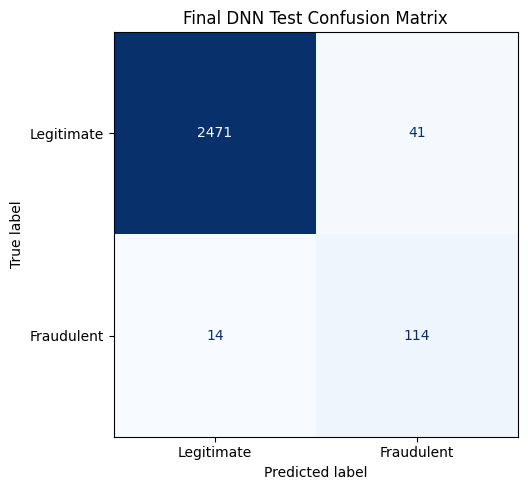

True Negatives: 2471
False Positives: 41
False Negatives: 14
True Positives: 114

False negative examples:


,title,fraudulent
212,Military Benefits Advocate,1
241,Urgent position for SQL BI Tester,1
353,Integration Engineer with HL7 & EMR.,1
428,MONEY MOTIVATED outside sales reps,1
453,Hotel Workers Needed,1


In [7]:
final_predictions = (
    dnn_test_scores >= selected_threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraudulent"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Final DNN Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "final_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

print("\nFalse negative examples:")
false_negatives = test_df.loc[
    (y_test == 1) & (final_predictions == 0),
    ["title", "fraudulent"]
]

display(false_negatives.head(5))

In [8]:
required_files = [
    MODEL_DIR / "decision_threshold.json",
    REPORT_DIR / "final_test_results.csv",
    REPORT_DIR / "threshold_analysis.csv",
    FIGURE_DIR / "threshold_analysis.png",
    FIGURE_DIR / "precision_recall_comparison.png",
    FIGURE_DIR / "final_test_confusion_matrix.png"
]

for path in required_files:
    assert path.is_file(), f"Missing file: {path}"
    print("PASS:", path.name)

with open(
    MODEL_DIR / "decision_threshold.json",
    "r",
    encoding="utf-8"
) as file:
    saved_config = json.load(file)

assert np.isclose(
    saved_config["decision_threshold"],
    selected_threshold
)

assert len(final_predictions) == len(y_test)

print("\nFinal evaluation artefacts verified.")

PASS: decision_threshold.json
PASS: final_test_results.csv
PASS: threshold_analysis.csv
PASS: threshold_analysis.png
PASS: precision_recall_comparison.png
PASS: final_test_confusion_matrix.png

Final evaluation artefacts verified.


## 3. Final Evaluation Conclusion

The JobShield model evaluation includes:

- Logistic Regression and DNN comparison
- Validation-based decision-threshold selection
- Precision-recall analysis
- Final held-out test evaluation
- Confusion matrix
- Saved performance metrics
- Saved threshold configuration

### Important Limitation

The DNN outputs a sigmoid score, but the score has
not undergone probability calibration.

It should therefore be described as an estimated
fraud score rather than a guaranteed probability
that an advertisement is fraudulent.

### Next Phase

Develop the JobShield Streamlit application using:

- The saved preprocessing pipeline
- The trained DNN
- The saved classification threshold